In [2]:

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = "../data"
VAL_DIR = os.path.join(BASE_DIR, "Validation")
TEST_DIR = os.path.join(BASE_DIR, "Test")
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

normalization_layer = tf.keras.layers.Rescaling(1./255)

val_ds_nor = val_ds.map(lambda images, labels: (normalization_layer(images), labels))
test_ds_nor = test_ds.map(lambda images, labels: (normalization_layer(images), labels))

AUTOTUNE = tf.data.AUTOTUNE
val_ds_final = val_ds_nor.cache().prefetch(buffer_size=AUTOTUNE)
test_ds_final = test_ds_nor.cache().prefetch(buffer_size=AUTOTUNE)

print('dataset loaded')

Found 800 files belonging to 2 classes.
Found 992 files belonging to 2 classes.
dataset loaded


In [4]:
simple_cnn = load_model("../models/mask_CNN_01.keras")
complex_cnn = load_model("../models/mask_complex_CNN_01.keras")
transfer = load_model("../models/facemask_mobilenetv2_best.keras")

print('models loaded')

models loaded


Evaluating simple CNN on test set...
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 144ms/step - accuracy: 0.9940 - f1-score: 0.6782 - loss: 0.0253 - precision: 0.9980 - recall: 0.9902
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step
Confusion Matrix:
[[482   1]
 [  5 504]]
Classification Report:
              precision    recall  f1-score   support

    WithMask       0.99      1.00      0.99       483
 WithoutMask       1.00      0.99      0.99       509

    accuracy                           0.99       992
   macro avg       0.99      0.99      0.99       992
weighted avg       0.99      0.99      0.99       992



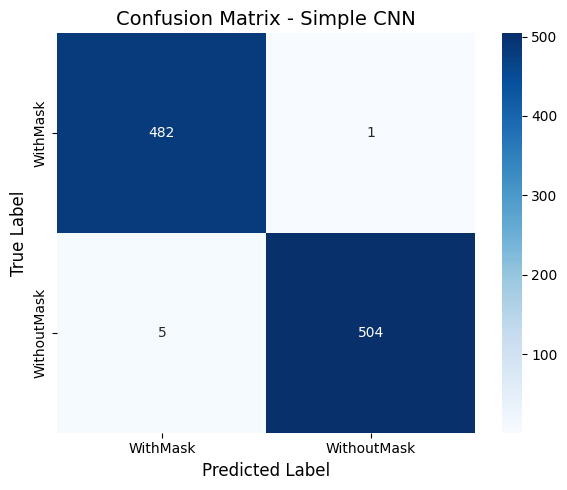

In [7]:
#simple cnn
print("Evaluating simple CNN on test set...")

test_results = simple_cnn.evaluate(test_ds_final, verbose=1)

y_pred_probs = simple_cnn.predict(test_ds_final, verbose=1)
y_true = np.concatenate([labels for _, labels in test_ds_final], axis=0)

y_true = y_true.astype(int).flatten()
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

conf_matrix = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(conf_matrix)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=['WithMask', 'WithoutMask']))

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['WithMask', 'WithoutMask'], 
            yticklabels=['WithMask', 'WithoutMask'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Simple CNN', fontsize=14)
plt.tight_layout()
plt.show()

Evaluating complex CNN on test set...
31/31 ━━━━━━━━━━━━━━━━━━━━ 29s 873ms/step - accuracy: 0.9940 - loss: 0.0406 - precision: 1.0000 - recall: 0.9882
31/31 ━━━━━━━━━━━━━━━━━━━━ 28s 888ms/step
F1-Score: 0.9941
Confusion Matrix:
[[483   0]
 [  6 503]]
Classification Report:
              precision    recall  f1-score   support

    WithMask       0.99      1.00      0.99       483
 WithoutMask       1.00      0.99      0.99       509

    accuracy                           0.99       992
   macro avg       0.99      0.99      0.99       992
weighted avg       0.99      0.99      0.99       992



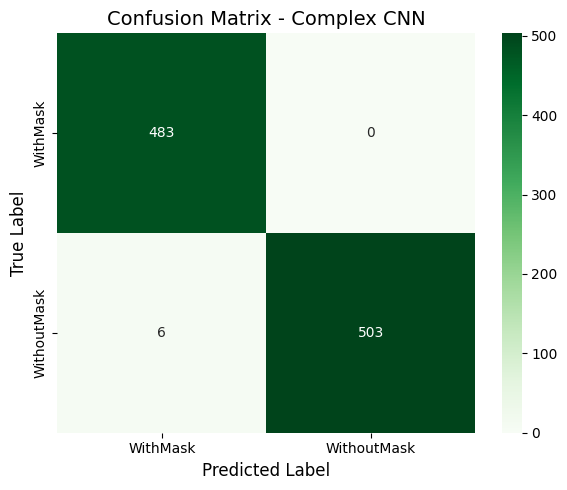

In [6]:
#complex cnn
print("Evaluating complex CNN on test set...")
test_results = complex_cnn.evaluate(test_ds_final, verbose=1)

y_pred_probs = complex_cnn.predict(test_ds_final, verbose=1)
y_true = np.concatenate([labels for _, labels in test_ds_final], axis=0)

y_true = y_true.astype(int).flatten()
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

f1 = f1_score(y_true, y_pred) #i forgot to put F1 score to trained model so i have to include it here
conf_matrix = confusion_matrix(y_true, y_pred)

print(f"F1-Score: {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=['WithMask', 'WithoutMask']))

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['WithMask', 'WithoutMask'], 
            yticklabels=['WithMask', 'WithoutMask'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Complex CNN', fontsize=14)
plt.tight_layout()
plt.show()

Evaluating transfer learning on test set...
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.4869 - loss: 5.6894 - precision: 0.0000e+00 - recall: 0.0000e+00
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step
Confusion Matrix:
[[483   0]
 [509   0]]
Classification Report:
              precision    recall  f1-score   support

    WithMask       0.49      1.00      0.65       483
 WithoutMask       0.00      0.00      0.00       509

    accuracy                           0.49       992
   macro avg       0.24      0.50      0.33       992
weighted avg       0.24      0.49      0.32       992



c:\Users\pc\anaconda3\envs\normal\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\pc\anaconda3\envs\normal\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\pc\anaconda3\envs\normal\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


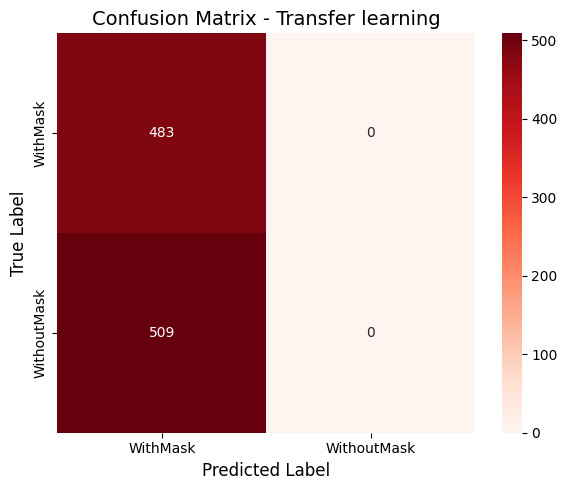

In [8]:
#transfer
print("Evaluating transfer learning on test set...")

test_results = transfer.evaluate(test_ds_final, verbose=1)

y_pred_probs = transfer.predict(test_ds_final, verbose=1)
y_true = np.concatenate([labels for _, labels in test_ds_final], axis=0)

y_true = y_true.astype(int).flatten()
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

conf_matrix = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(conf_matrix)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=['WithMask', 'WithoutMask']))

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['WithMask', 'WithoutMask'], 
            yticklabels=['WithMask', 'WithoutMask'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Transfer learning', fontsize=14)
plt.tight_layout()
plt.show()

<Figure size 600x500 with 0 Axes>

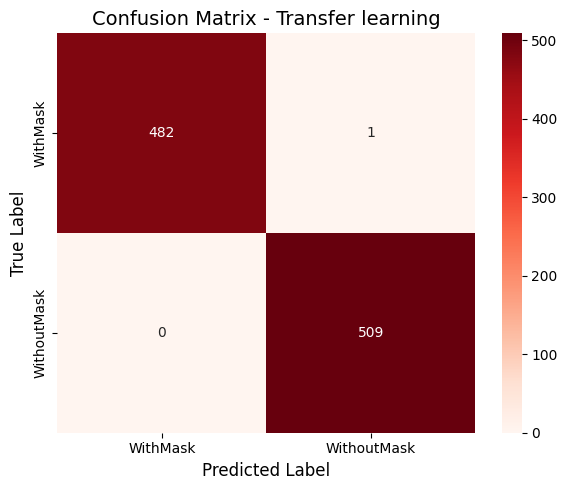

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Dữ liệu confusion matrix
cm = np.array([[482, 1], [0, 509]])

# Thiết lập kích thước biểu đồ
plt.figure(figsize=(6, 5))

# Vẽ heatmap sử dụng Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['WithMask', 'WithoutMask'], 
            yticklabels=['WithMask', 'WithoutMask'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Transfer learning', fontsize=14)
plt.tight_layout()
plt.show()